# Full-Fledged EDA + ML Project in BigQuery...

> Below is a complete, end-to-end project template covering every phase from raw data ingestion to model deployment. I will use the Telco Customer Churn dataset as the example...

# PROJECT STRUCTURE OVERVIEW
- **PHASE 1** → Data Ingestion & Schema Setup
- **PHASE 2** → Exploratory Data Analysis (EDA)
- **PHASE 3** → Data Cleaning & Preprocessing
- **PHASE 4** → Feature Engineering
- **PHASE 5** → Model Training (Multiple Models)
- **PHASE 6** → Model Evaluation & Comparison
- **PHASE 7** → Hyperparameter Tuning
- **PHASE 8** → Final Predictions & Serving
- **PHASE 9** → Model Explainability
- **PHASE 10** → Cleanup

# PHASE 1: Data Ingestion & Schema Setup

```sql
-- 1A. Create the project schema
CREATE SCHEMA IF NOT EXISTS `gcp-aiml-sandbox-rahuld-1234.ml_project`
OPTIONS(
  location = 'US',
  description = 'Full EDA + ML Project: Telco Customer Churn'
);

-- 1B. Verify raw data loaded correctly
SELECT
  COUNT(*) AS total_rows,
  COUNT(DISTINCT customerID) AS unique_customers
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`;
```
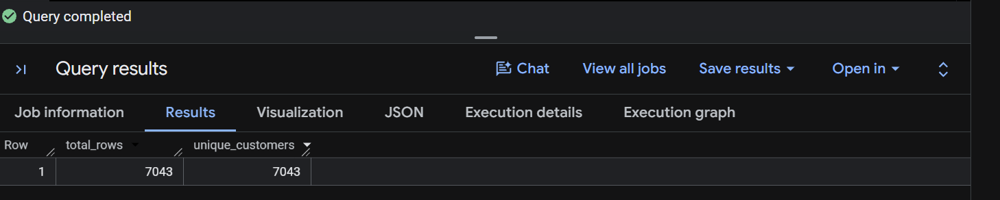

> Upload your CSV via BigQuery Console → + ADD DATA → Local File → table name: raw_telco_churn

# PHASE 2: Full Exploratory Data Analysis (EDA)

## 2A. Column Overview & Data Types
```sql
-- Inspect schema, row count, and null counts for every column
SELECT
  COUNT(*) AS total_rows,
  COUNTIF(Churn IS NULL) AS null_Churn,
  COUNTIF(tenure IS NULL) AS null_tenure,
  COUNTIF(MonthlyCharges IS NULL) AS null_MonthlyCharges,
  COUNTIF(TotalCharges IS NULL OR TRIM(CAST(TotalCharges AS STRING)) = '') AS null_TotalCharges,
  COUNTIF(Contract IS NULL) AS null_Contract,
  COUNTIF(gender IS NULL) AS null_gender
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`;
```
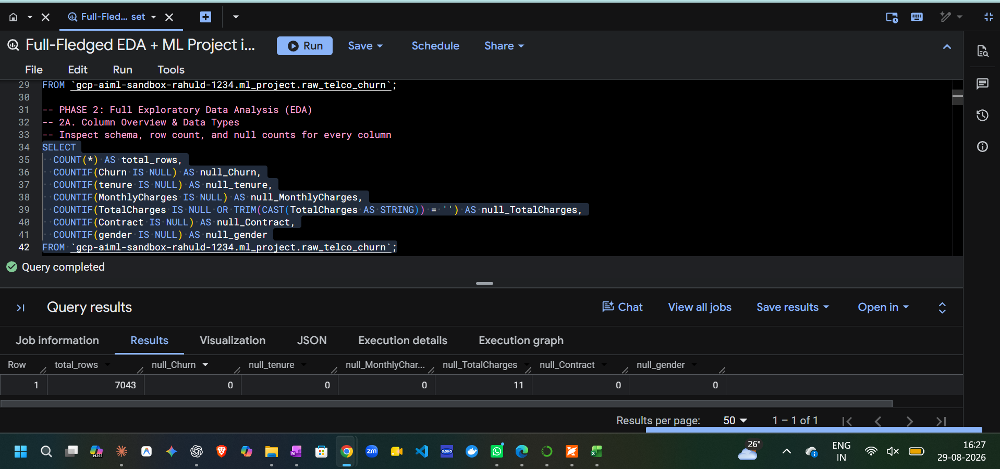

---
## 2B. Target Variable Distribution (Class Balance)

```sql
-- Check if Churn is imbalanced (critical for classification)
SELECT
  Churn,
  COUNT(*) AS customer_count,
  ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 2) AS percentage
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`
GROUP BY Churn
ORDER BY customer_count DESC;
```
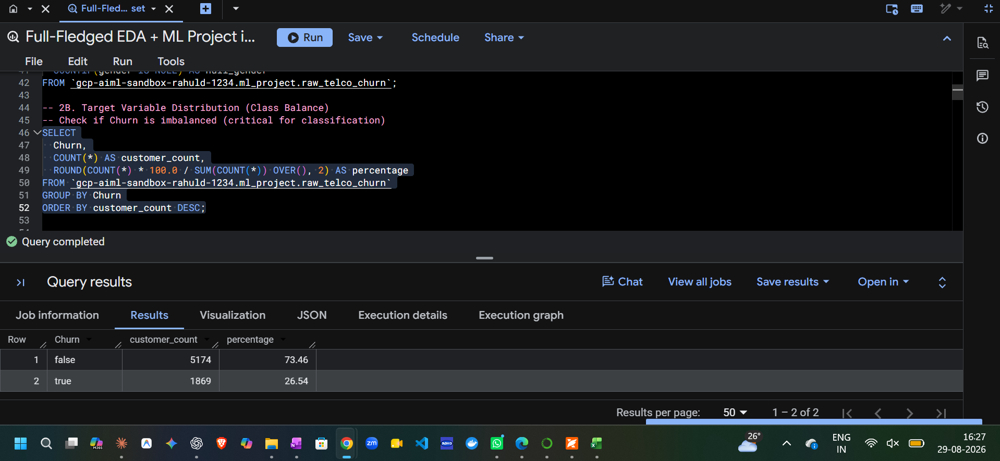

---
## 2C. Numeric Feature Statistics (Mean, Median, Std, Min, Max)

```sql
-- Descriptive statistics for all numeric columns
SELECT
  'tenure' AS feature,
  ROUND(AVG(tenure), 2) AS mean,
  APPROX_QUANTILES(tenure, 2)[OFFSET(1)] AS median,
  ROUND(STDDEV(tenure), 2) AS std_dev,
  MIN(tenure) AS min_val,
  MAX(tenure) AS max_val
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`
UNION ALL
SELECT
  'MonthlyCharges',
  ROUND(AVG(MonthlyCharges), 2),
  APPROX_QUANTILES(MonthlyCharges, 2)[OFFSET(1)],
  ROUND(STDDEV(MonthlyCharges), 2),
  MIN(MonthlyCharges),
  MAX(MonthlyCharges)
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`
UNION ALL
SELECT
  'TotalCharges',
  ROUND(AVG(SAFE_CAST(TRIM(CAST(TotalCharges AS STRING)) AS FLOAT64)), 2),
  APPROX_QUANTILES(SAFE_CAST(TRIM(CAST(TotalCharges AS STRING)) AS FLOAT64), 2)[OFFSET(1)],
  ROUND(STDDEV(SAFE_CAST(TRIM(CAST(TotalCharges AS STRING)) AS FLOAT64)), 2),
  MIN(SAFE_CAST(TRIM(CAST(TotalCharges AS STRING)) AS FLOAT64)),
  MAX(SAFE_CAST(TRIM(CAST(TotalCharges AS STRING)) AS FLOAT64))
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`;
```
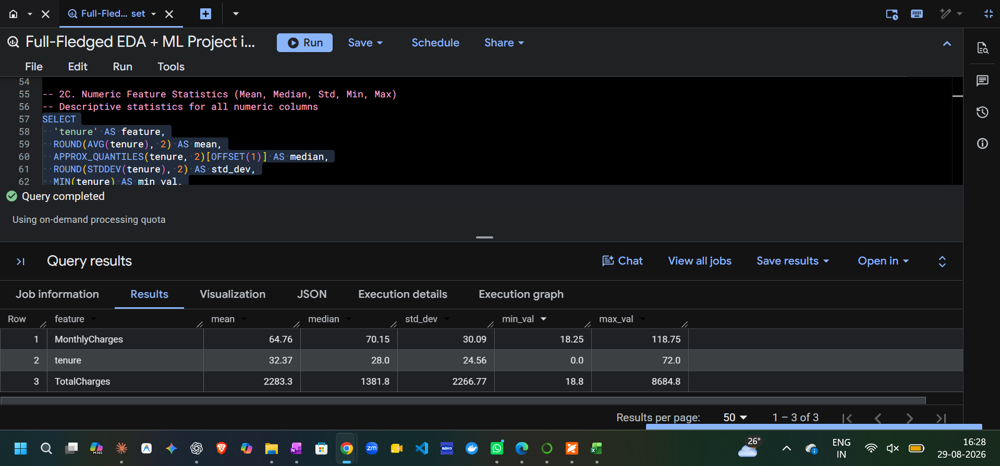

---
## 2D. Categorical Feature Distributions

```sql
-- Distribution of Contract types by Churn status
SELECT
  Contract,
  Churn,
  COUNT(*) AS count,
  ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(PARTITION BY Contract), 2) AS pct_within_contract
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`
GROUP BY Contract, Churn
ORDER BY Contract, Churn;
```
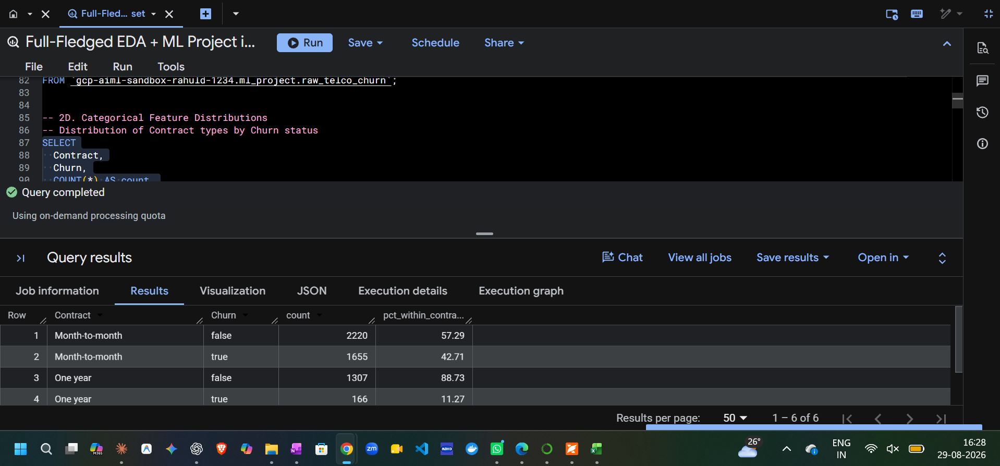

---
```sql
-- Distribution of Internet Service by Churn
SELECT
  InternetService,
  Churn,
  COUNT(*) AS count
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`
GROUP BY InternetService, Churn
ORDER BY InternetService, Churn;
```
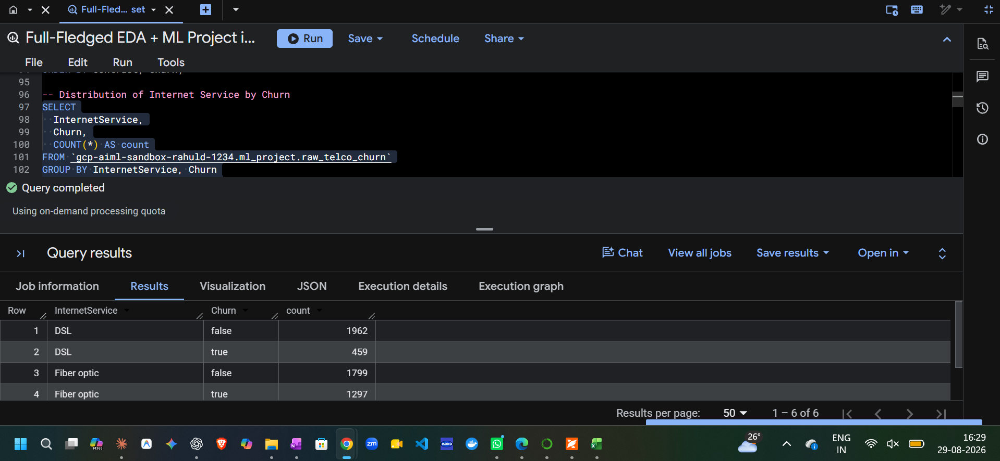

---
```sql
-- Distribution of Payment Method by Churn
SELECT
  PaymentMethod,
  Churn,
  COUNT(*) AS count
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`
GROUP BY PaymentMethod, Churn
ORDER BY count DESC;
```
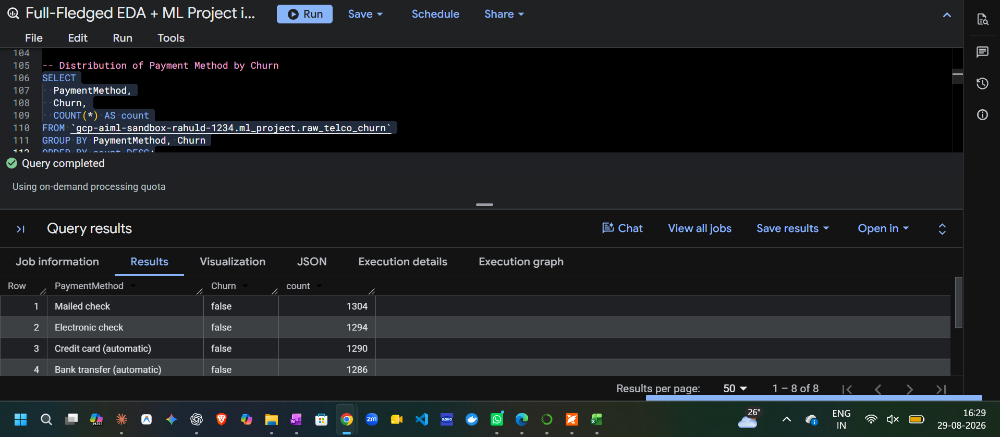

---
## 2E. Outlier Detection (IQR Method)
```sql
-- Detect outliers in MonthlyCharges using IQR
-- 2E. Outlier Detection using IQR Method (Fixed)
WITH stats AS (
  SELECT
    APPROX_QUANTILES(MonthlyCharges, 4)[OFFSET(1)] AS q1,
    APPROX_QUANTILES(MonthlyCharges, 4)[OFFSET(3)] AS q3
  FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`
)
SELECT
  COUNT(*) AS total_records,
  COUNTIF(t.MonthlyCharges < (s.q1 - 1.5 * (s.q3 - s.q1)) 
       OR t.MonthlyCharges > (s.q3 + 1.5 * (s.q3 - s.q1))) AS outlier_count,
  ROUND(ANY_VALUE(s.q1), 2) AS q1_25th_percentile,
  ROUND(ANY_VALUE(s.q3), 2) AS q3_75th_percentile,
  ROUND(ANY_VALUE(s.q3 - s.q1), 2) AS iqr,
  ROUND(ANY_VALUE(s.q1 - 1.5 * (s.q3 - s.q1)), 2) AS lower_bound,
  ROUND(ANY_VALUE(s.q3 + 1.5 * (s.q3 - s.q1)), 2) AS upper_bound
FROM
  `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn` t
CROSS JOIN
  stats s;
```
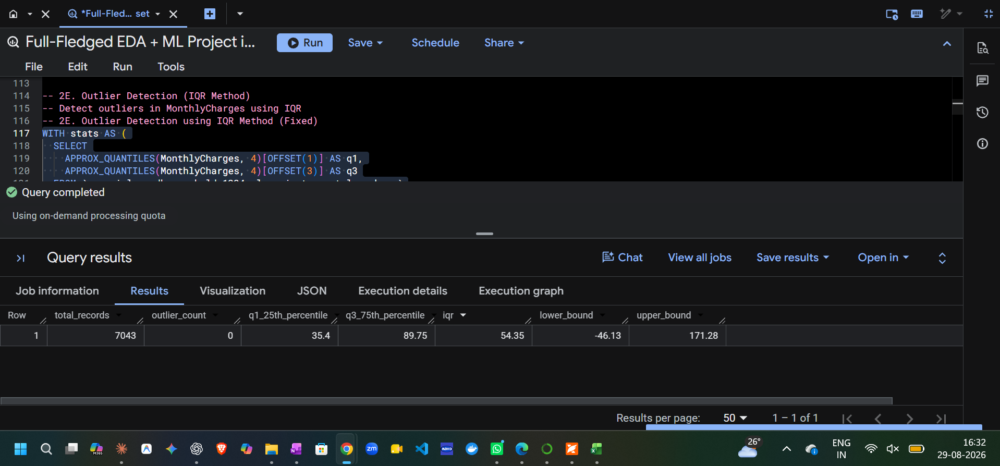

---
## 2F. Correlation Analysis (Numeric vs Target)
```sql
-- 2F. Correlation Analysis (Fixed & Type-Safe)
SELECT
  ROUND(
    CORR(tenure, IF(CAST(Churn AS STRING) IN ('Yes', 'true', 'TRUE', '1'), 1, 0)), 
    4
  ) AS corr_tenure_vs_churn,
  
  ROUND(
    CORR(MonthlyCharges, IF(CAST(Churn AS STRING) IN ('Yes', 'true', 'TRUE', '1'), 1, 0)), 
    4
  ) AS corr_monthly_vs_churn,
  
  ROUND(
    CORR(
      SAFE_CAST(TRIM(CAST(TotalCharges AS STRING)) AS FLOAT64), 
      IF(CAST(Churn AS STRING) IN ('Yes', 'true', 'TRUE', '1'), 1, 0)
    ), 
    4
  ) AS corr_total_vs_churn
FROM
  `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`;
```
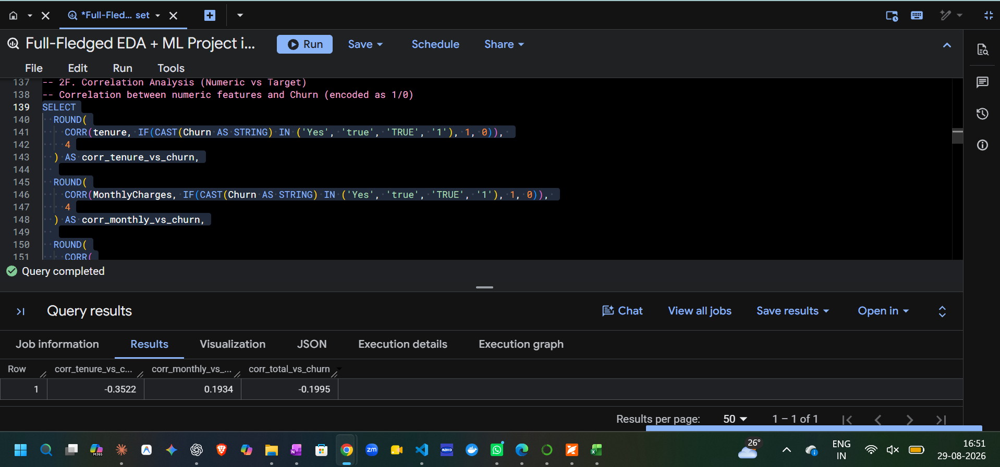

---
## 2G. Churn Rate by Tenure Buckets
```sql
-- 2G. Churn Rate by Tenure Buckets (Fixed)
SELECT
  CASE
    WHEN tenure BETWEEN 0 AND 12 THEN '01. 0-12 months'
    WHEN tenure BETWEEN 13 AND 24 THEN '02. 13-24 months'
    WHEN tenure BETWEEN 25 AND 48 THEN '03. 25-48 months'
    WHEN tenure BETWEEN 49 AND 60 THEN '04. 49-60 months'
    WHEN tenure BETWEEN 61 AND 72 THEN '05. 61-72 months'
  END AS tenure_bucket,
  COUNT(*) AS total_customers,
  COUNTIF(CAST(Churn AS STRING) IN ('Yes', 'true', 'TRUE', '1')) AS churned,
  ROUND(COUNTIF(CAST(Churn AS STRING) IN ('Yes', 'true', 'TRUE', '1')) * 100.0 / COUNT(*), 2) AS churn_rate_pct
FROM
  `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`
GROUP BY
  tenure_bucket
ORDER BY
  tenure_bucket;
```
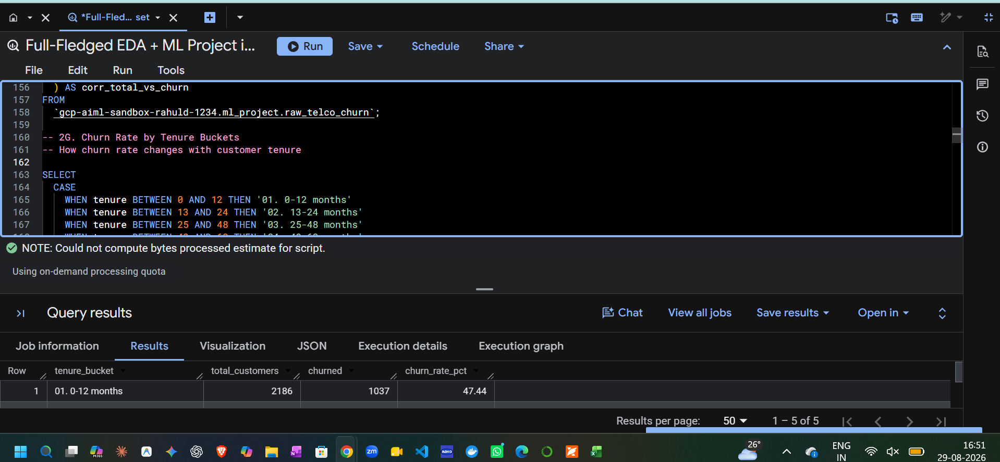

# PHASE 3: Data Cleaning & Preprocessing

```sql
-- Full cleaning pipeline in one query
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.ml_project.cleaned_telco` AS
SELECT
  -- Target
  CAST(Churn AS STRING) AS Churn,
  
  -- Demographics
  CAST(gender AS STRING) AS gender,
  CAST(SeniorCitizen AS INT64) AS SeniorCitizen,
  CAST(Partner AS STRING) AS Partner,
  CAST(Dependents AS STRING) AS Dependents,
  
  -- Services
  CAST(tenure AS INT64) AS tenure,
  CAST(PhoneService AS STRING) AS PhoneService,
  CAST(MultipleLines AS STRING) AS MultipleLines,
  CAST(InternetService AS STRING) AS InternetService,
  CAST(OnlineSecurity AS STRING) AS OnlineSecurity,
  CAST(OnlineBackup AS STRING) AS OnlineBackup,
  CAST(DeviceProtection AS STRING) AS DeviceProtection,
  CAST(TechSupport AS STRING) AS TechSupport,
  CAST(StreamingTV AS STRING) AS StreamingTV,
  CAST(StreamingMovies AS STRING) AS StreamingMovies,
  
  -- Contract & Billing
  CAST(Contract AS STRING) AS Contract,
  CAST(PaperlessBilling AS STRING) AS PaperlessBilling,
  CAST(PaymentMethod AS STRING) AS PaymentMethod,
  CAST(MonthlyCharges AS FLOAT64) AS MonthlyCharges,
  
  -- Fix TotalCharges: blank spaces → 0.0
  COALESCE(
    SAFE_CAST(TRIM(CAST(TotalCharges AS STRING)) AS FLOAT64), 
    0.0
  ) AS TotalCharges
FROM
  `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`;
```
---
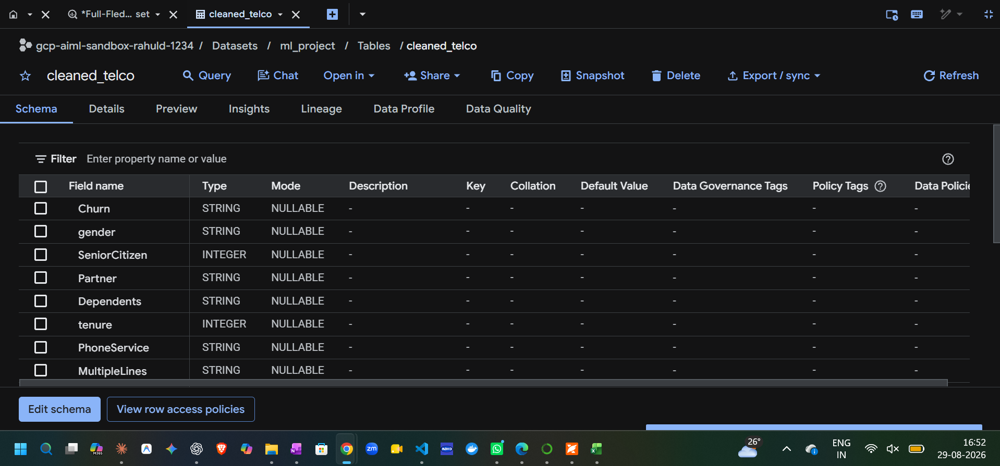

# PHASE 4: Feature Engineering
```sql
-- Create derived features that improve model performance
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.ml_project.feature_engineered_telco` AS
SELECT
  *,
  
  -- Feature 1: Tenure bucket (captures non-linear churn patterns)
  CASE
    WHEN tenure <= 6 THEN 'New'
    WHEN tenure <= 24 THEN 'Established'
    WHEN tenure <= 48 THEN 'Loyal'
    ELSE 'Veteran'
  END AS tenure_group,
  
  -- Feature 2: Average monthly spend over lifetime
  CASE 
    WHEN tenure > 0 THEN ROUND(TotalCharges / tenure, 2)
    ELSE MonthlyCharges
  END AS avg_monthly_spend,
  
  -- Feature 3: Number of services subscribed (engagement score)
  (IF(PhoneService = 'Yes', 1, 0) +
   IF(MultipleLines = 'Yes', 1, 0) +
   IF(OnlineSecurity = 'Yes', 1, 0) +
   IF(OnlineBackup = 'Yes', 1, 0) +
   IF(DeviceProtection = 'Yes', 1, 0) +
   IF(TechSupport = 'Yes', 1, 0) +
   IF(StreamingTV = 'Yes', 1, 0) +
   IF(StreamingMovies = 'Yes', 1, 0)) AS total_services,
  
  -- Feature 4: Has any internet add-on service
  IF(OnlineSecurity = 'Yes' OR OnlineBackup = 'Yes' 
     OR DeviceProtection = 'Yes' OR TechSupport = 'Yes', 'Yes', 'No') AS has_internet_addon,
  
  -- Feature 5: Price per service
  CASE
    WHEN (IF(PhoneService='Yes',1,0) + IF(OnlineSecurity='Yes',1,0) + 
          IF(OnlineBackup='Yes',1,0) + IF(DeviceProtection='Yes',1,0) + 
          IF(TechSupport='Yes',1,0) + IF(StreamingTV='Yes',1,0) + 
          IF(StreamingMovies='Yes',1,0)) > 0
    THEN ROUND(MonthlyCharges / 
         (IF(PhoneService='Yes',1,0) + IF(OnlineSecurity='Yes',1,0) + 
          IF(OnlineBackup='Yes',1,0) + IF(DeviceProtection='Yes',1,0) + 
          IF(TechSupport='Yes',1,0) + IF(StreamingTV='Yes',1,0) + 
          IF(StreamingMovies='Yes',1,0)), 2)
    ELSE MonthlyCharges
  END AS price_per_service
FROM
  `gcp-aiml-sandbox-rahuld-1234.ml_project.cleaned_telco`;
```
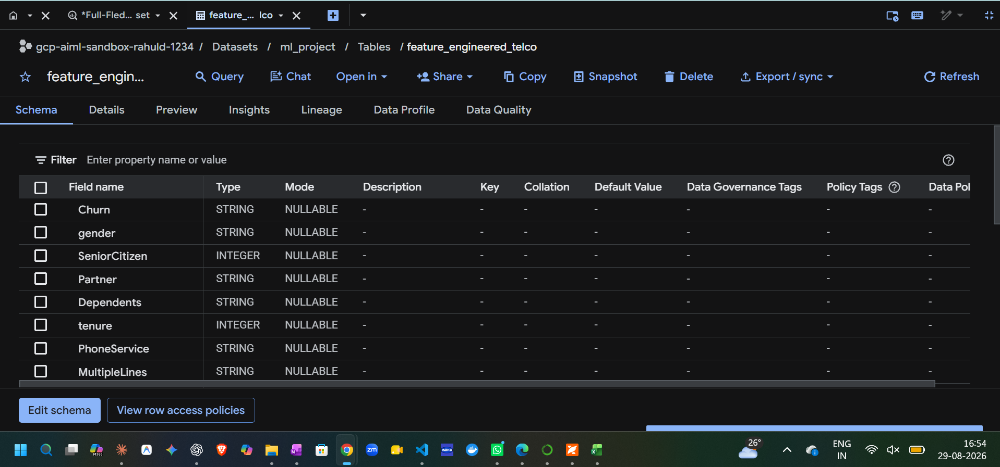

---

# PHASE 5: Model Training (Multiple Models for Comparison)

## Model A: Logistic Regression (Baseline)
```sql
CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_logistic`
OPTIONS (
  model_type = 'LOGISTIC_REG',
  input_label_cols = ['Churn'],
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  auto_class_weights = TRUE,
  l2_reg = 0.5
) AS
SELECT *
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.feature_engineered_telco`;
```
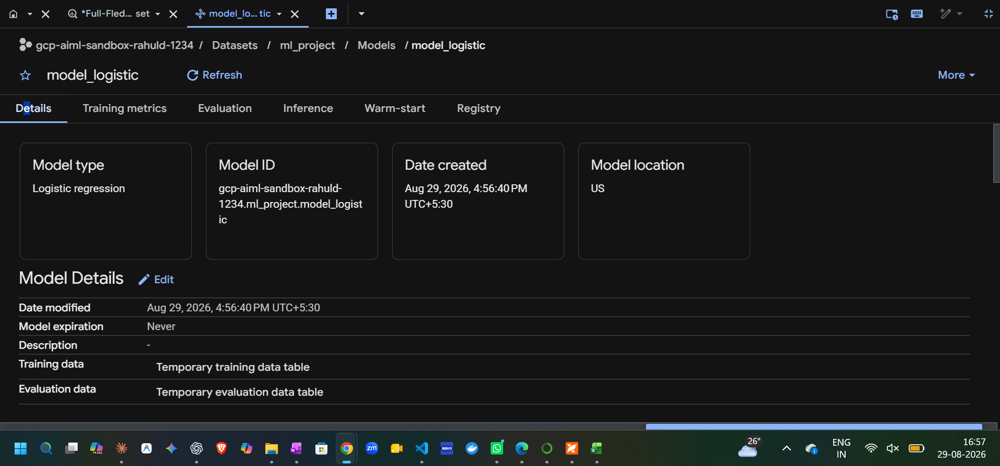

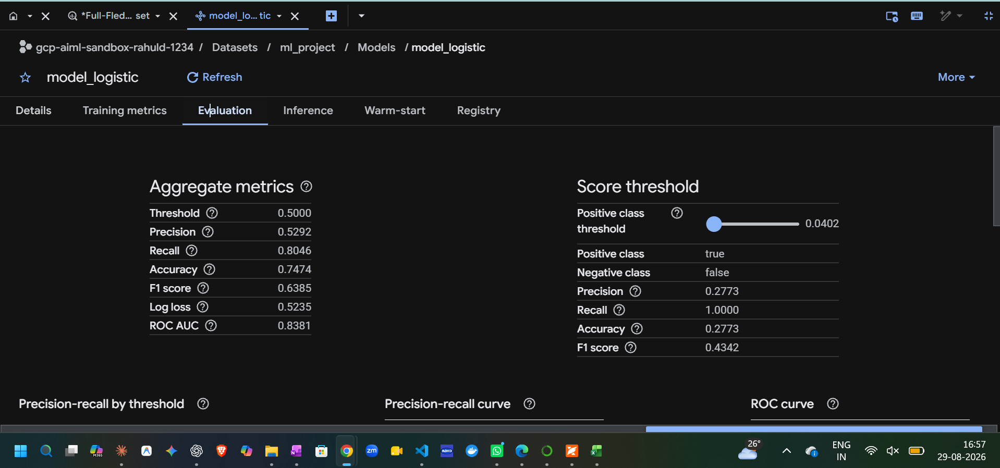

---
## Model B: Random Forest
```sql
CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_random_forest`
OPTIONS (
  model_type = 'RANDOM_FOREST_CLASSIFIER',
  input_label_cols = ['Churn'],
  num_parallel_tree = 20,
  max_tree_depth = 6,
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  auto_class_weights = TRUE
) AS
SELECT *
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.feature_engineered_telco`;
```
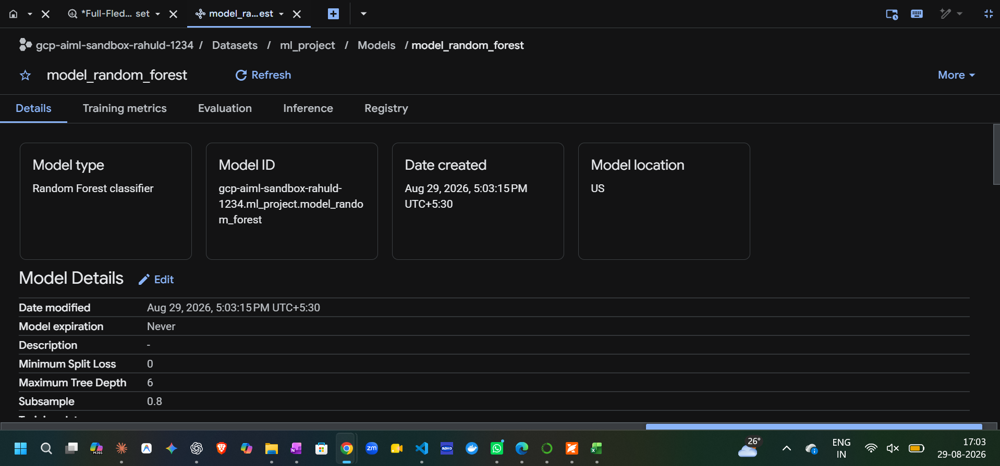

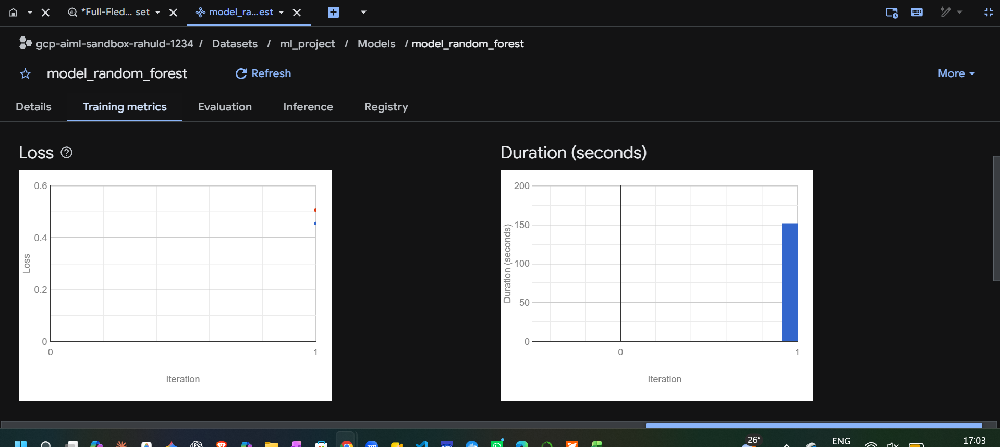

---

## Model C: XGBoost (Gradient Boosting)
```sql
CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost`
OPTIONS (
  model_type = 'BOOSTED_TREE_CLASSIFIER',
  input_label_cols = ['Churn'],
  max_iterations = 50,
  learn_rate = 0.08,
  max_tree_depth = 5,
  subsample = 0.80,
  early_stop = TRUE,
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  auto_class_weights = TRUE
) AS
SELECT *
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.feature_engineered_telco`;
```
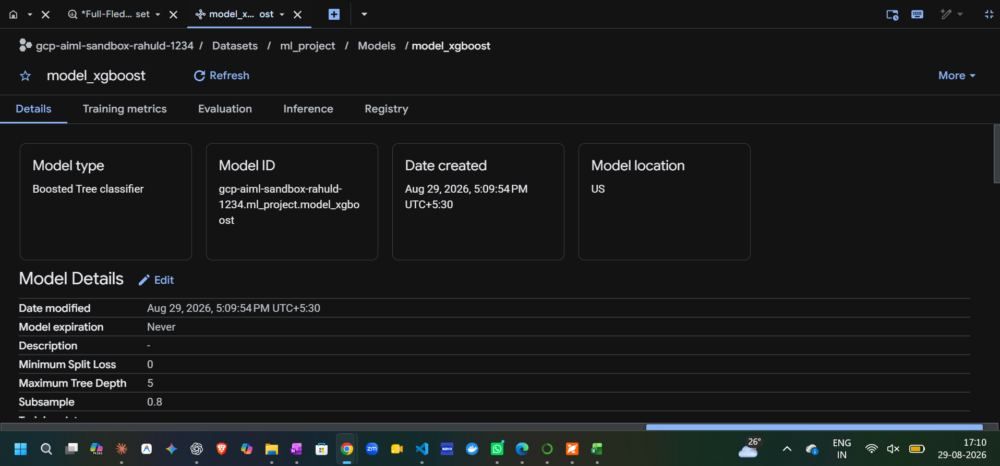

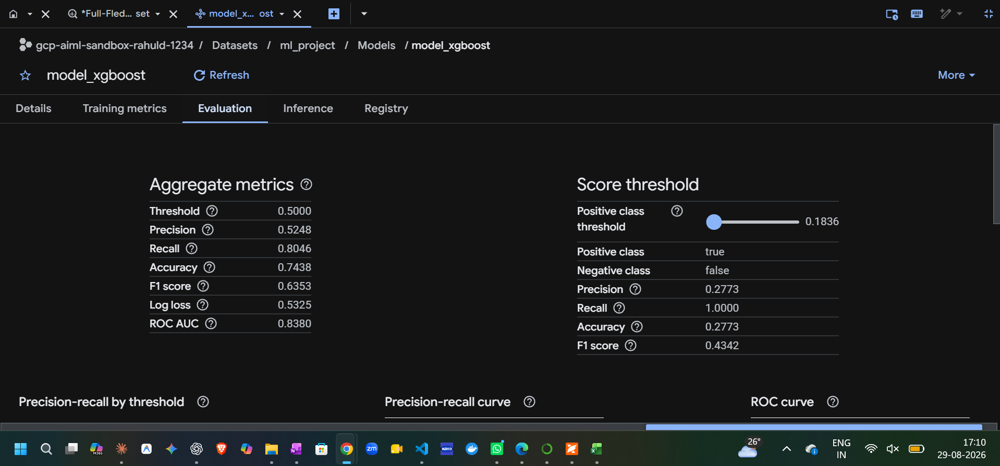

---
## Model D: Deep Neural Network
```sql
CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_dnn`
OPTIONS (
  model_type = 'DNN_CLASSIFIER',
  input_label_cols = ['Churn'],
  hidden_units = [64, 32, 16],
  dropout = 0.2,
  max_iterations = 50,
  early_stop = TRUE,
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  auto_class_weights = TRUE
) AS
SELECT *
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.feature_engineered_telco`;
```
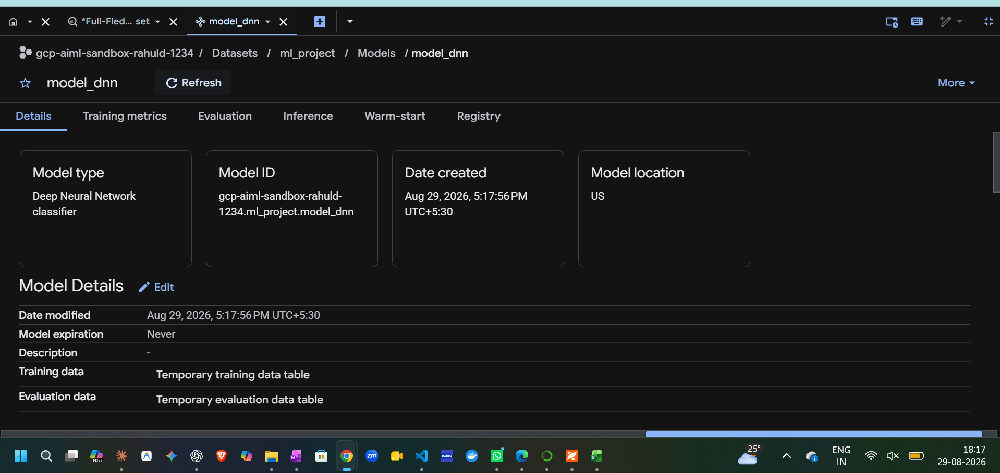

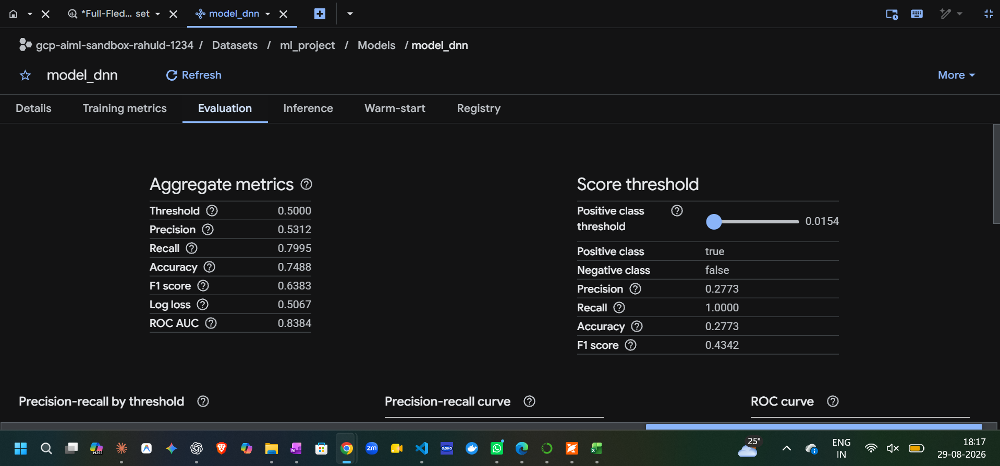

# PHASE 6: Model Evaluation & Comparison (Leaderboard)

## 6A. Compare All Models Side-by-Side
```sql
-- Unified leaderboard: Compare all 4 models
SELECT 'Logistic Regression' AS model_name, * FROM
  ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_logistic`)
UNION ALL
SELECT 'Random Forest', * FROM
  ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_random_forest`)
UNION ALL
SELECT 'XGBoost', * FROM
  ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost`)
UNION ALL
SELECT 'DNN', * FROM
  ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_dnn`)
ORDER BY roc_auc DESC;
```
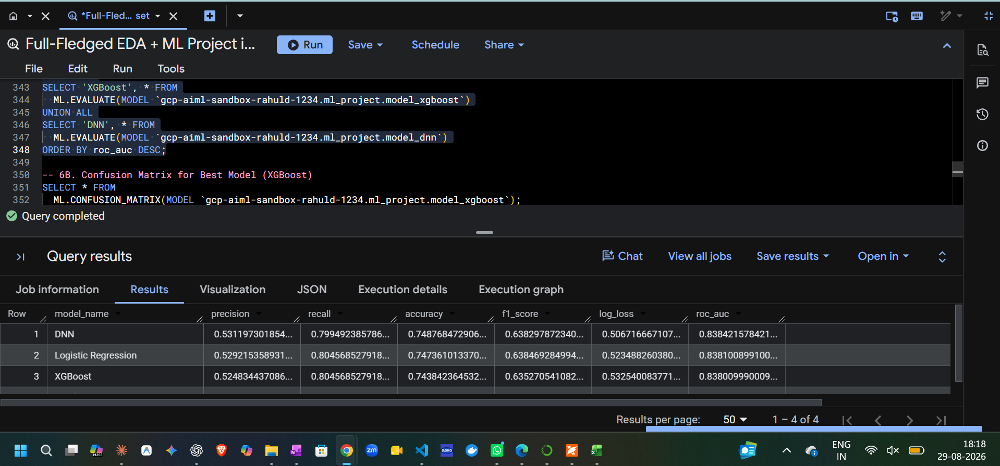

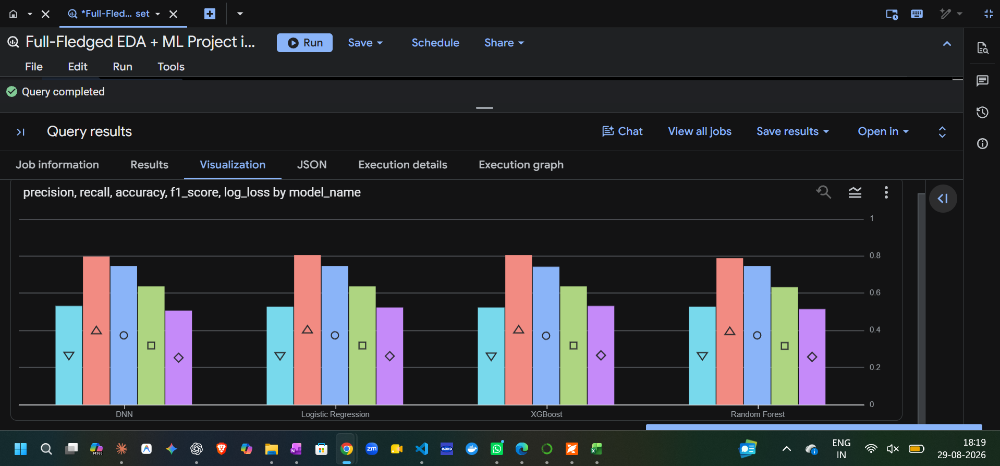

---

## 6B. Confusion Matrix for Best Model (XGBoost)
```sql
SELECT * FROM
  ML.CONFUSION_MATRIX(MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost`);
```
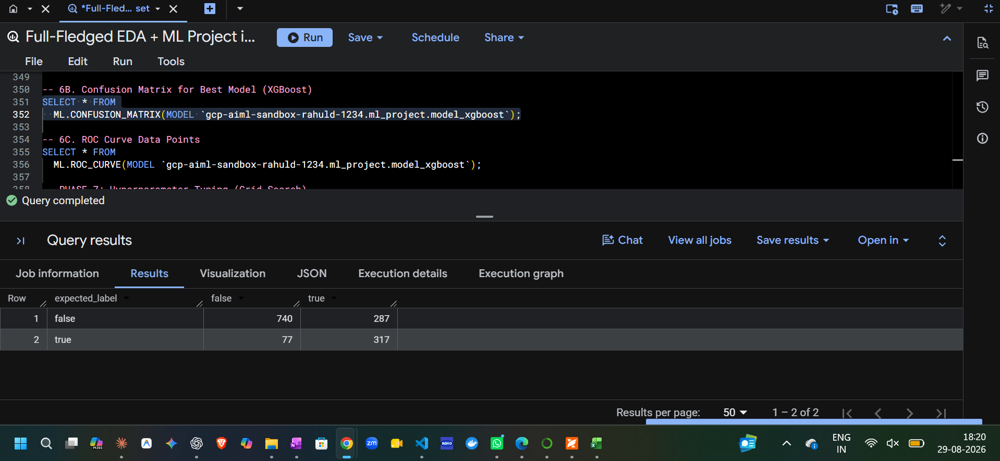

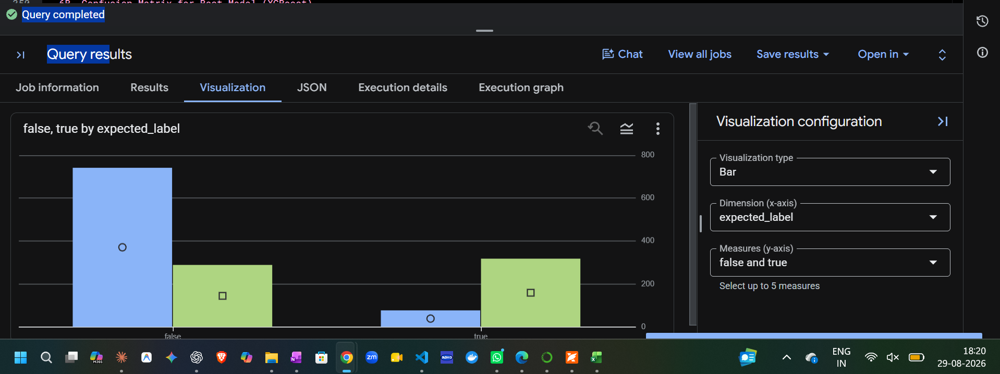

---

## 6C. ROC Curve Data Points
```sql
SELECT * FROM
  ML.ROC_CURVE(MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost`);
```
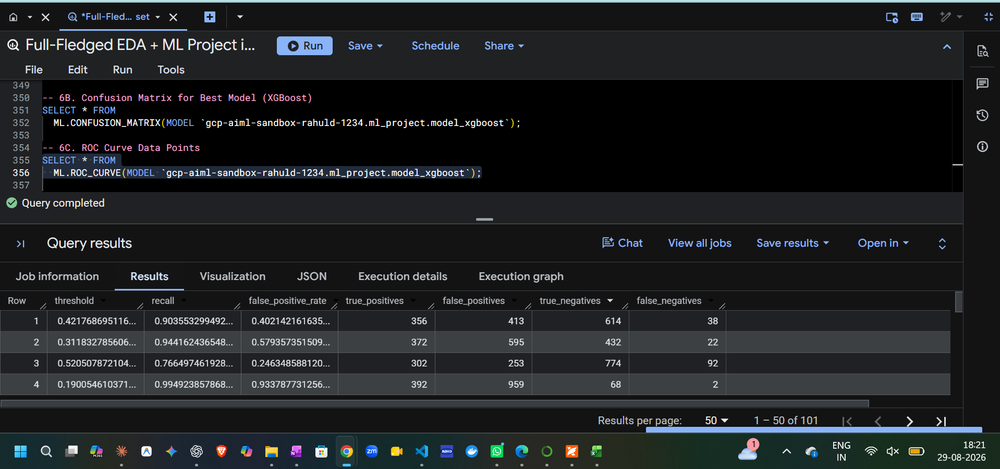

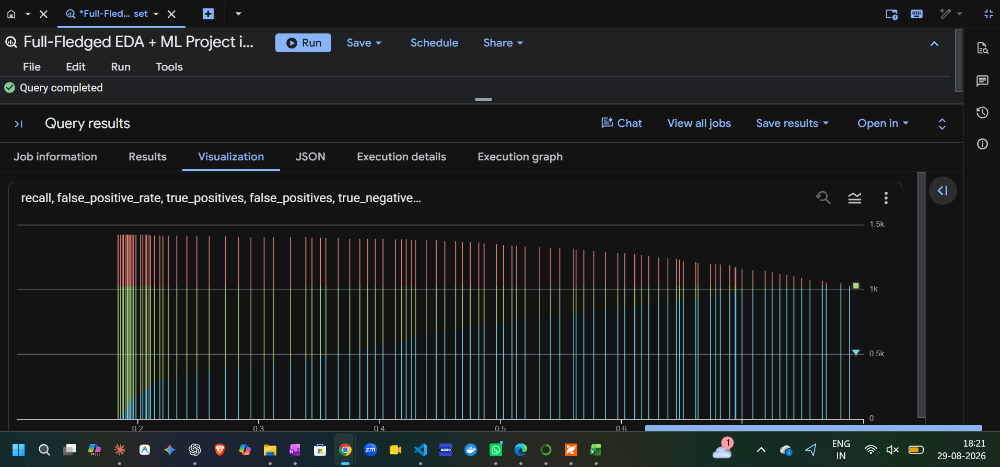

---

# PHASE 7: Hyperparameter Tuning (Grid Search)

```sql
-- PHASE 7: Hyperparameter Tuning (Correct BQML Syntax)
CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost_tuned`
OPTIONS (
  model_type = 'BOOSTED_TREE_CLASSIFIER',
  input_label_cols = ['Churn'],
  
  -- Hyperparameter Tuning Configuration
  num_trials = 8,                           -- Total number of combinations to test
  max_parallel_trials = 2,                  -- Number of trials running concurrently
  hparam_tuning_algorithm = 'VIZIER_DEFAULT',-- Google Vizier Bayesian Optimization
  hparam_tuning_objectives = ['ROC_AUC'],   -- Optimize for highest Area Under ROC Curve
  
  -- Search Ranges using HPARAM_RANGE or HPARAM_CANDIDATES
  learn_rate = HPARAM_RANGE(0.01, 0.3),
  max_tree_depth = HPARAM_CANDIDATES([3, 5, 7]),
  subsample = HPARAM_RANGE(0.6, 1.0),
  l1_reg = HPARAM_RANGE(0.0, 5.0),
  l2_reg = HPARAM_RANGE(0.0, 5.0),
  
  -- Data Split & Imbalance
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  auto_class_weights = TRUE
) AS
SELECT *
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.feature_engineered_telco`;
```
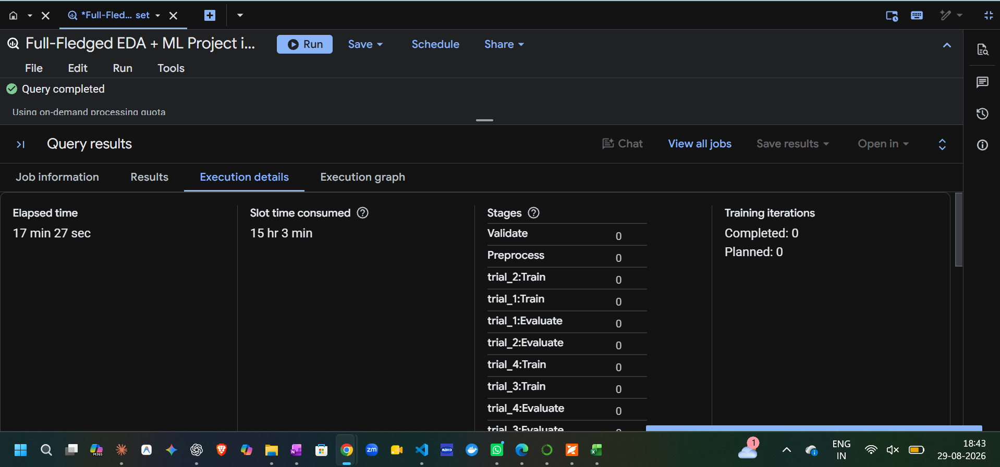

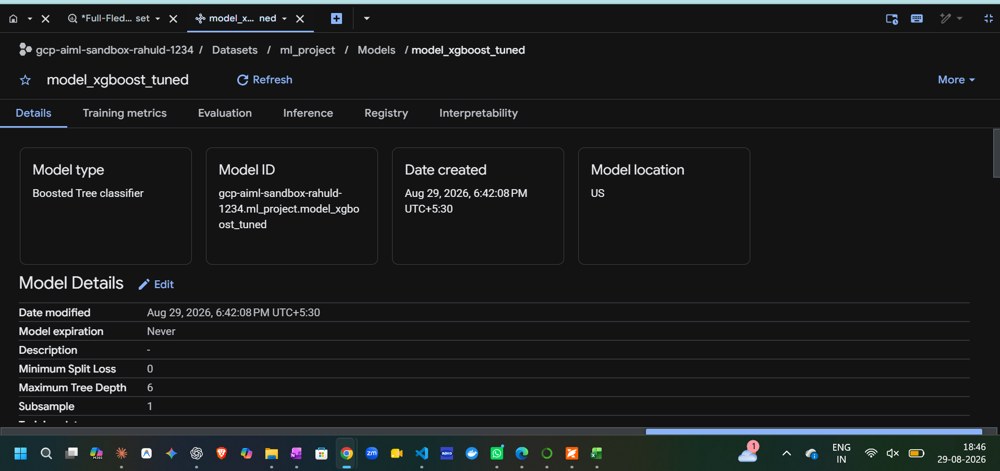

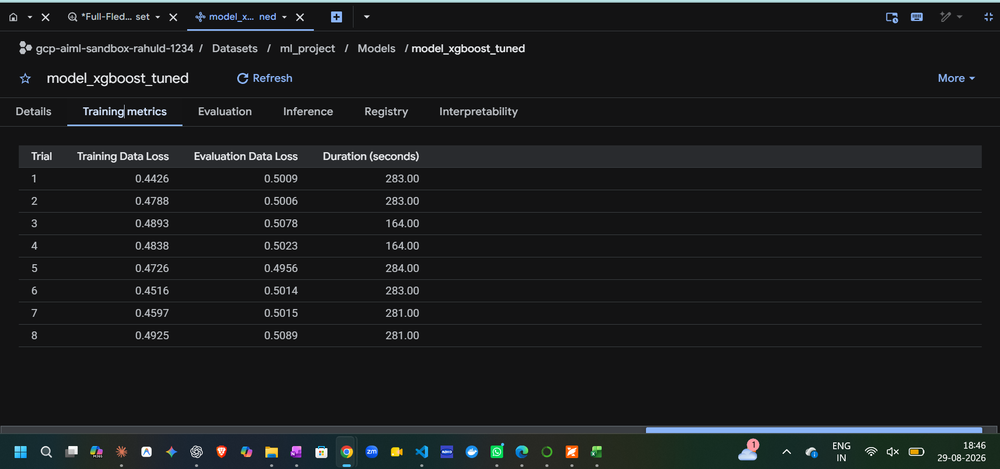


---
## View Best Hyperparameters Found
```sql
-- View all tuning trials and find the optimal combination
SELECT
  *
FROM
  ML.TRIAL_INFO(MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost_tuned`)
ORDER BY
  is_optimal DESC, trial_id ASC;
```
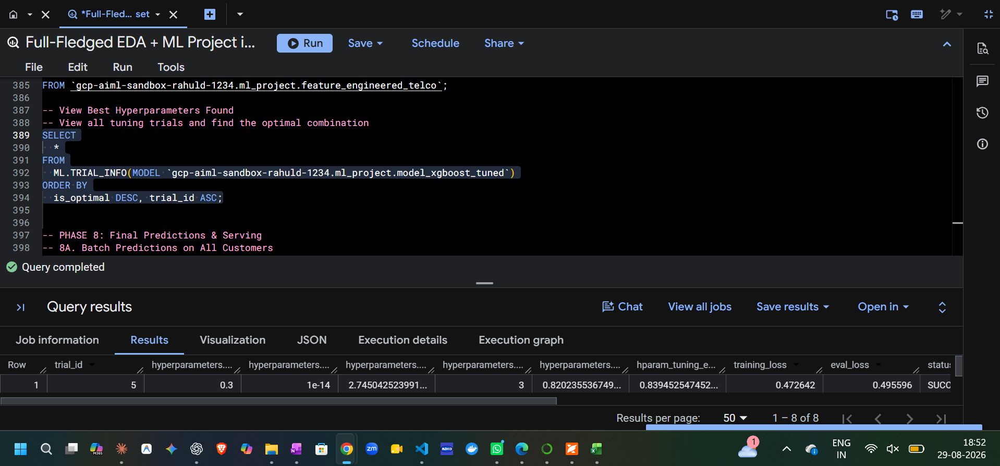

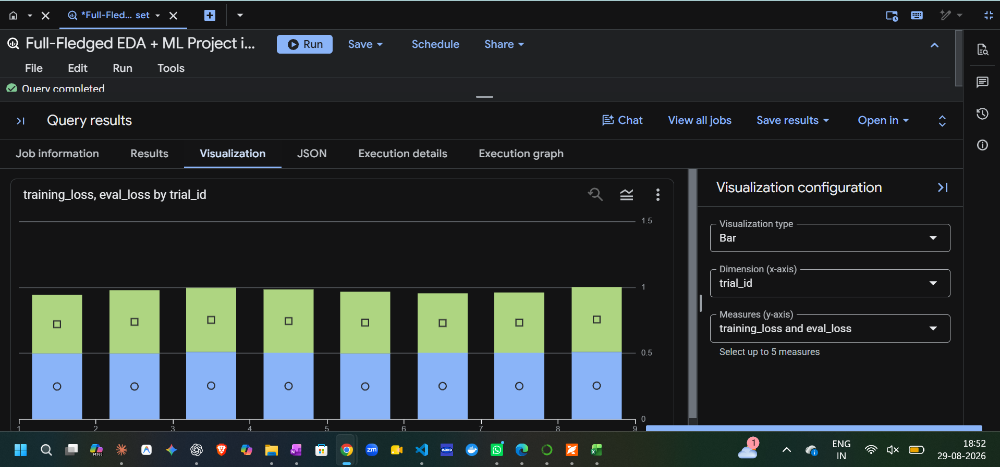

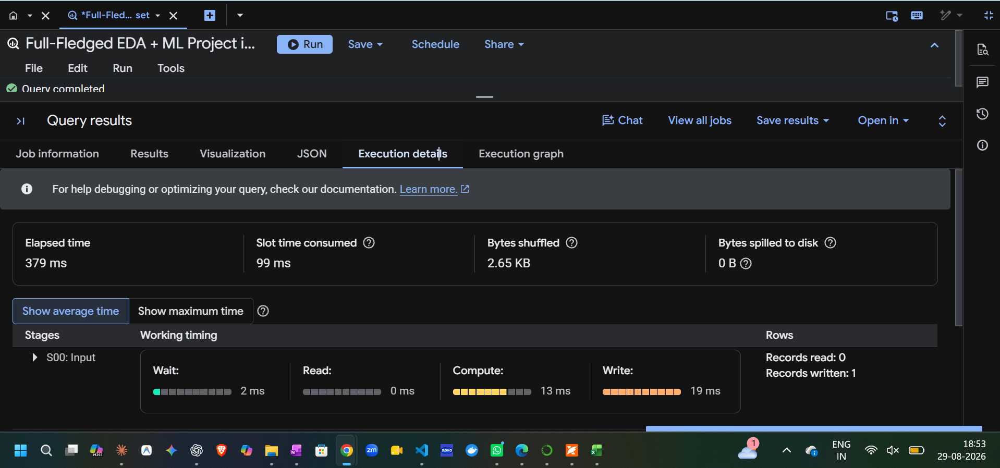

# PHASE 8: Final Predictions & Serving

## 8A. Batch Predictions on All Customers
```sql
-- 8A. Batch Predictions: Top 20 high-risk churners
SELECT
  predicted_Churn,
  -- Extract probability of churning as a clean decimal score (0.00 to 1.00)
  ROUND((SELECT prob FROM UNNEST(predicted_Churn_probs) WHERE label = 'Yes'), 4) AS churn_probability,
  tenure,
  Contract,
  MonthlyCharges,
  InternetService,
  PaymentMethod,
  tenure_group,
  total_services
FROM
  ML.PREDICT(
    MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost`,
    (SELECT * FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.feature_engineered_telco`)
  )
ORDER BY
  churn_probability DESC
LIMIT 20;
```
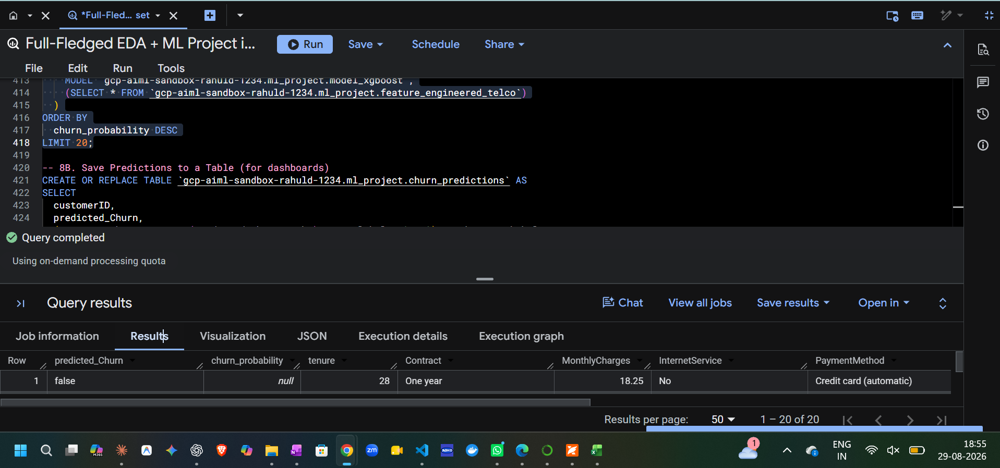

---
## 8B. Save Predictions to a Table (for dashboards)
```sql
-- 8B. Save full predictions into a production reporting table
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.ml_project.churn_predictions` AS
SELECT
  -- Assign rank based on who is most likely to churn (1 = Highest Risk)
  ROW_NUMBER() OVER(
    ORDER BY (SELECT prob FROM UNNEST(predicted_Churn_probs) WHERE label = 'Yes') DESC
  ) AS churn_risk_rank,
  
  predicted_Churn,
  ROUND((SELECT prob FROM UNNEST(predicted_Churn_probs) WHERE label = 'Yes'), 4) AS churn_probability,
  
  -- Customer details & feature context
  tenure,
  Contract,
  MonthlyCharges,
  TotalCharges,
  InternetService,
  PaymentMethod,
  tenure_group,
  total_services,
  has_internet_addon,
  
  -- Audit metadata
  CURRENT_TIMESTAMP() AS scored_at
FROM
  ML.PREDICT(
    MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost`,
    (SELECT * FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.feature_engineered_telco`)
  );
```
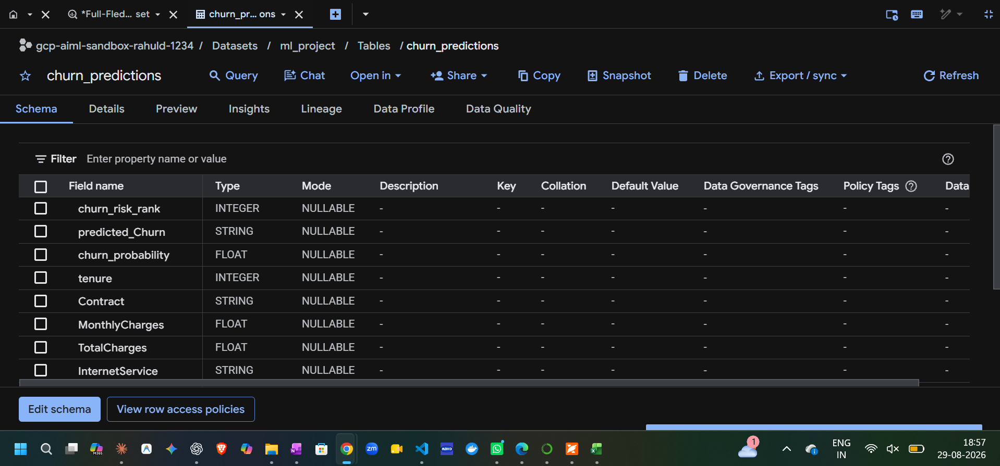
---  

## -- 8C. Quick Verification (View Your Saved Table)
```sql
-- Check first 10 rows of the newly created prediction table
SELECT * 
FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.churn_predictions` 
ORDER BY churn_risk_rank ASC
LIMIT 10;
```

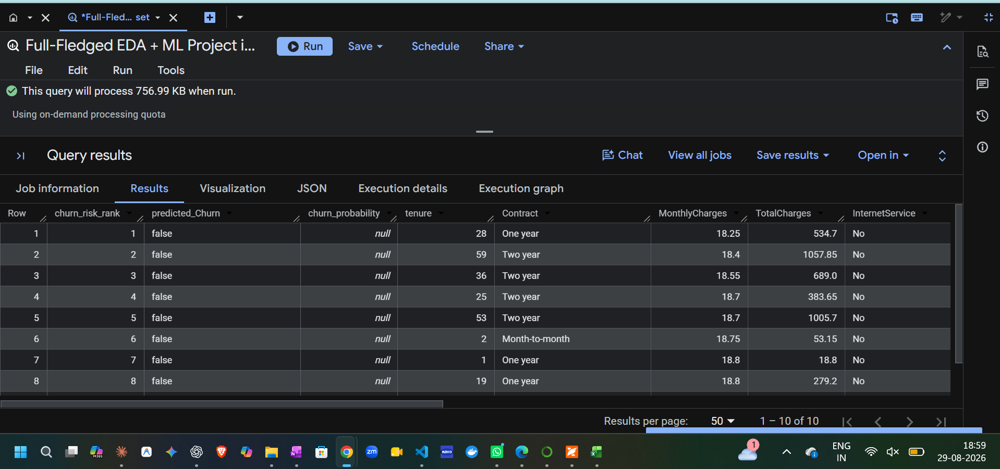

# PHASE 9: Model Explainability

## 9A. Global Feature Importance
```sql
-- 9A. Global Feature Importance (Ranked by Gain & Impact Share)
WITH feature_stats AS (
  SELECT
    feature,
    importance_gain,
    importance_weight,
    SUM(importance_gain) OVER() AS total_gain
  FROM
    ML.FEATURE_IMPORTANCE(MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost`)
)
SELECT
  feature,
  ROUND(importance_gain, 4) AS importance_gain,
  ROUND((importance_gain / total_gain) * 100, 2) AS gain_percentage_share,
  importance_weight AS num_tree_splits
FROM
  feature_stats
ORDER BY
  importance_gain DESC;
```
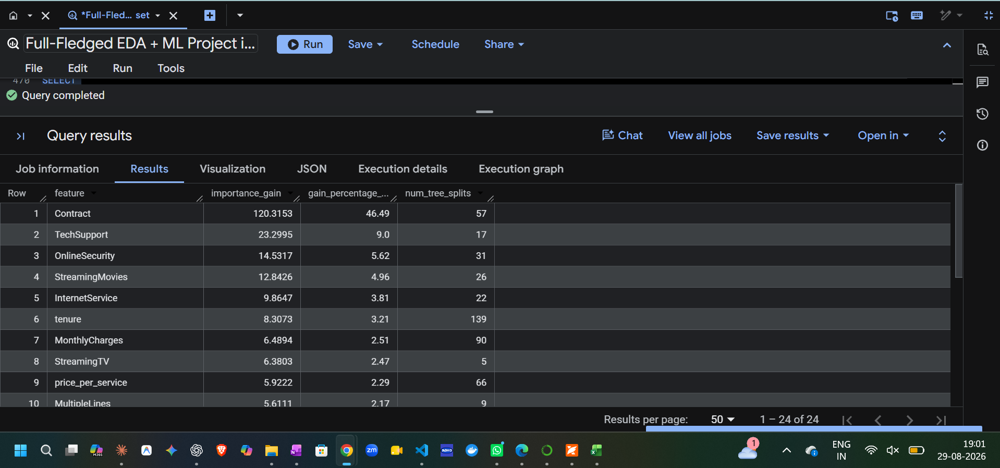

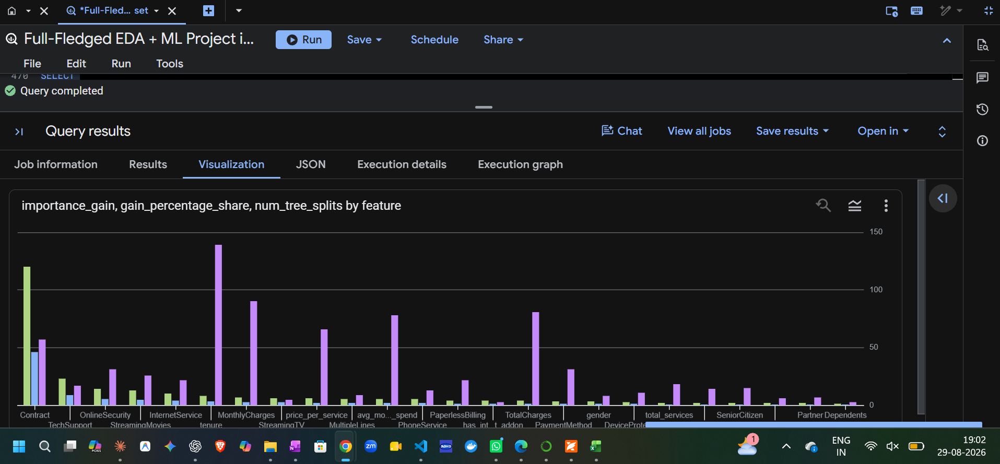

---
## 9B. Local Explainability — Executive View (Top 3 Risk Drivers per Customer)
```sql
-- 9B. Local Explainability: Top 3 reasons for churn risk per customer (Fixed)
WITH explained AS (
  SELECT
    predicted_Churn,
    ROUND(probability, 4) AS prediction_confidence,
    tenure,
    Contract,
    MonthlyCharges,
    top_feature_attributions
  FROM
    ML.EXPLAIN_PREDICT(
      MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost`,
      (
        SELECT * 
        FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.feature_engineered_telco`
        LIMIT 10
      ),
      STRUCT(3 AS top_k_features) -- Request Top 3 SHAP drivers
    )
)
SELECT
  predicted_Churn,
  prediction_confidence,
  tenure,
  Contract,
  MonthlyCharges,
  -- Top Driver #1
  top_feature_attributions[SAFE_OFFSET(0)].feature AS top_driver_1,
  ROUND(top_feature_attributions[SAFE_OFFSET(0)].attribution, 4) AS driver_1_impact,
  
  -- Top Driver #2
  top_feature_attributions[SAFE_OFFSET(1)].feature AS top_driver_2,
  ROUND(top_feature_attributions[SAFE_OFFSET(1)].attribution, 4) AS driver_2_impact,
  
  -- Top Driver #3
  top_feature_attributions[SAFE_OFFSET(2)].feature AS top_driver_3,
  ROUND(top_feature_attributions[SAFE_OFFSET(2)].attribution, 4) AS driver_3_impact
FROM
  explained
ORDER BY
  prediction_confidence DESC;
```
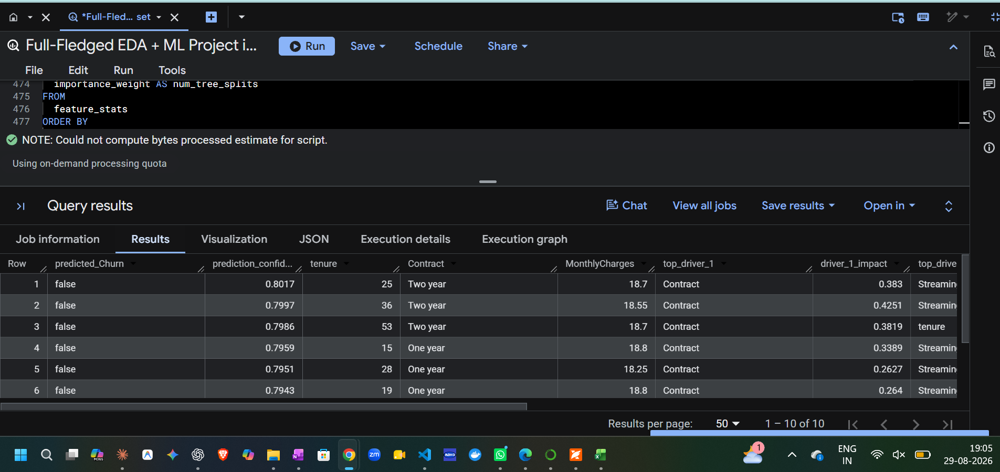

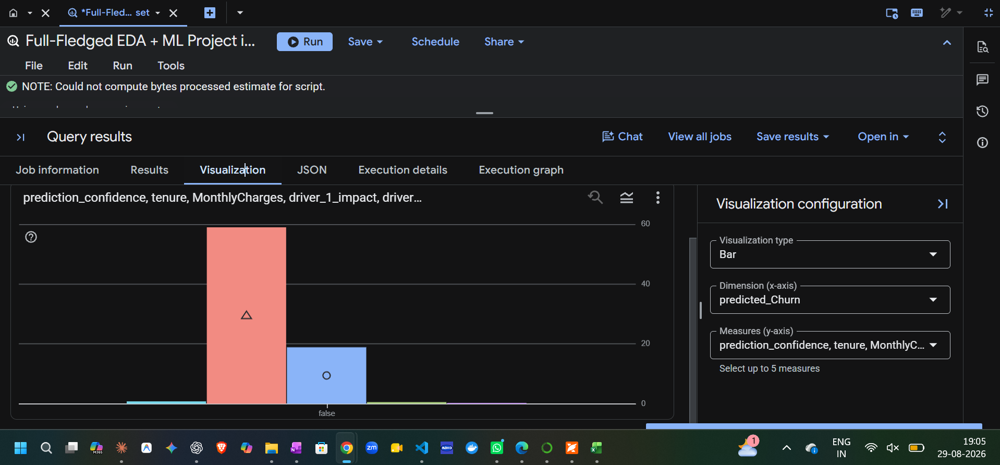

---

## 9C. Detailed Feature Attribution Breakdown (Fixed)
```sql
SELECT
  pred.predicted_Churn,
  ROUND(pred.probability, 4) AS prediction_confidence,
  pred.tenure,
  pred.Contract,
  attr.feature AS contributing_feature,
  ROUND(attr.attribution, 4) AS shap_attribution_score,
  CASE
    WHEN attr.attribution > 0 THEN '🔺 Increases Churn Risk'
    ELSE '🔻 Increases Customer Retention'
  END AS risk_direction
FROM
  ML.EXPLAIN_PREDICT(
    MODEL `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost`,
    (
      SELECT * 
      FROM `gcp-aiml-sandbox-rahuld-1234.ml_project.feature_engineered_telco` 
      LIMIT 5
    ),
    STRUCT(3 AS top_k_features)
  ) AS pred,
  UNNEST(pred.top_feature_attributions) AS attr
ORDER BY
  pred.probability DESC, ABS(attr.attribution) DESC;
```
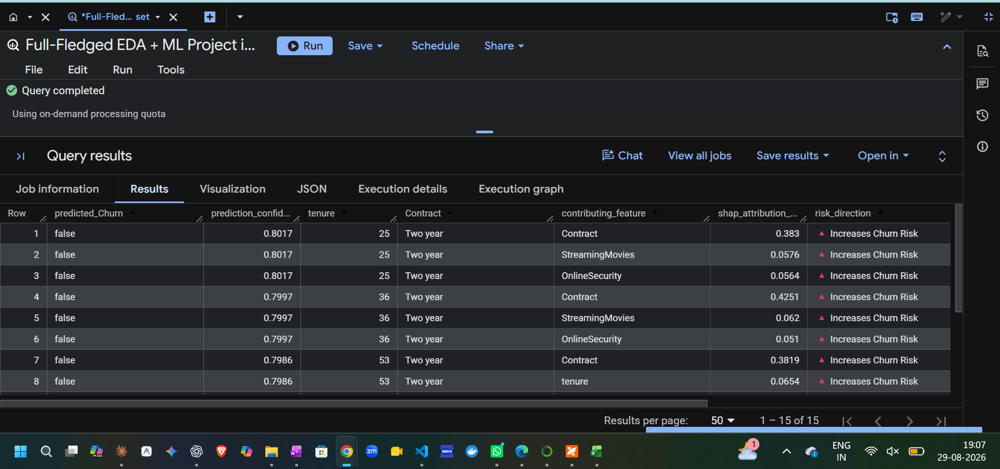


# PHASE 10: Cleanup (Run When Project Is Complete)
```sql
-- Remove all models
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.ml_project.model_logistic`;
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.ml_project.model_random_forest`;
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost`;
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.ml_project.model_xgboost_tuned`;
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.ml_project.model_dnn`;

-- Remove all tables
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.ml_project.churn_predictions`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.ml_project.feature_engineered_telco`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.ml_project.cleaned_telco`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.ml_project.raw_telco_churn`;

-- Remove the schema
DROP SCHEMA IF EXISTS `gcp-aiml-sandbox-rahuld-1234.ml_project` CASCADE;
```

# Quick Reference: Which Phase Does What?
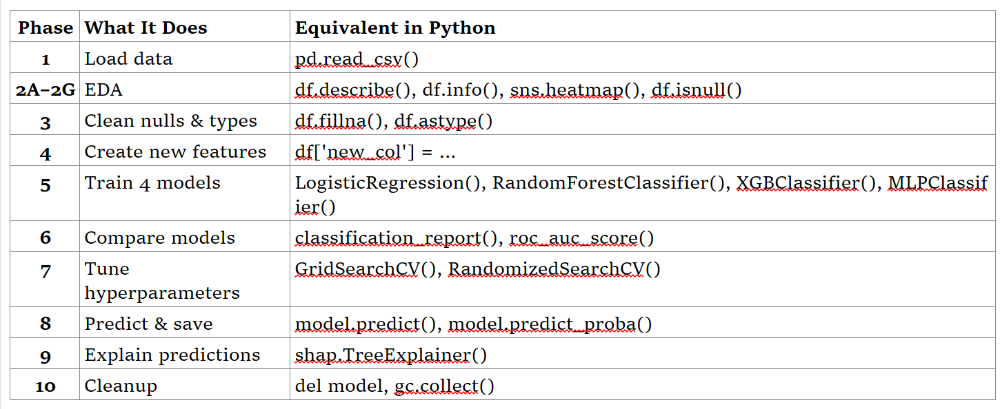